Testing to see if lateral inhibition still works with feature neurons starting from zero and receiving biases rather than just starting in their states

In [1]:
import scipy.integrate as int
import matplotlib.pyplot as plt
import numpy as np

In [26]:
#We are going to define activation functions for feature and memory separately
beta_feature = 2 #Sharpness of the tanh activation
def f_feature(xvec):
    return np.tanh(beta_feature*xvec) #Shift and scale to [0,1]

beta_memory = 3 #Sharpness of the softmax activation function
center_memory = 0.5 #Centering the sigmoid
def f_memory(xvec):
    return np.tanh(beta_memory*(xvec - center_memory))*0.5+0.5



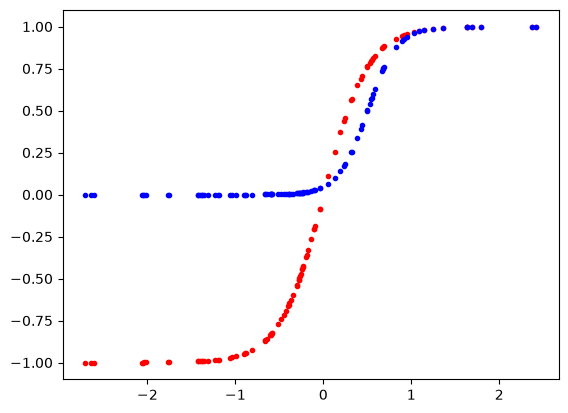

In [27]:
#Test these activation functions out on random numbers
rands = np.random.standard_normal(100)
plt.plot(rands,f_feature(rands),'r.')
plt.plot(rands,f_memory(rands),'b.')

In [35]:
#Binary error correction task, so rows are target code words. 
#nColumns is the number of features, nRows is the number of memories

codewordMatrix = np.asarray([[1,1,1],
                                [-1,-1,-1]])
nFeatures = np.shape(codewordMatrix)[1]
nMemories = np.shape(codewordMatrix)[0]
featureStrengthMult = 1 #Maximum that a weighted sum in the memory matrix could be
featureBiases = np.asarray([-1,-1,1])*(1/3)*featureStrengthMult
biasOnTime = 0.5 #How long biases stay on
#Construct the array of rhs functions
#NOTE: DEFAULT ARGUMENT TRICK REQUIRED TO BAKE IN CORRECT NUMBERS IN PYTHON
rhs = []
for i in range(nFeatures):
    rhs.append(
        lambda t, x, ymems, featidx=i: -x + np.dot(np.copy(codewordMatrix[:,featidx]),ymems) + featureBiases[featidx]*(t <= biasOnTime)
    )
buffer_factor = 0.9
lateral_inhibition = 1/(beta_memory/2)*buffer_factor #This should be the theoretical limit for single-point equilibrium in WTA
self_weight = 0
for j in range(nMemories):
    rhs.append(
        lambda x, yfeats, ymems, memidx=j:
          -x + np.dot(np.copy(codewordMatrix[memidx,:]),yfeats) 
          - lateral_inhibition*np.dot(np.ones(nMemories),ymems) + lateral_inhibition*ymems[memidx]
          + self_weight*ymems[memidx]
    )
#Time constant
tau = 1/10
def odefun(t,statevec):
    yfeats = f_feature(statevec[0:nFeatures])
    ymems = f_memory(statevec[nFeatures:])
    allRHS = np.zeros(np.size(statevec))
    for i in range(nFeatures):
        allRHS[i] = rhs[i](t,statevec[i],ymems)
    for j in range(nMemories):
        imem = nFeatures + j
        allRHS[imem] = rhs[imem](statevec[imem],yfeats,ymems)
    return allRHS*(1/tau)

#Construct initial values
iVals = np.asarray([0,0,0,0,0])

In [36]:
tlimits = [0,1]
output = int.solve_ivp(odefun,tlimits,iVals,atol=1e-6,rtol=1e-6)

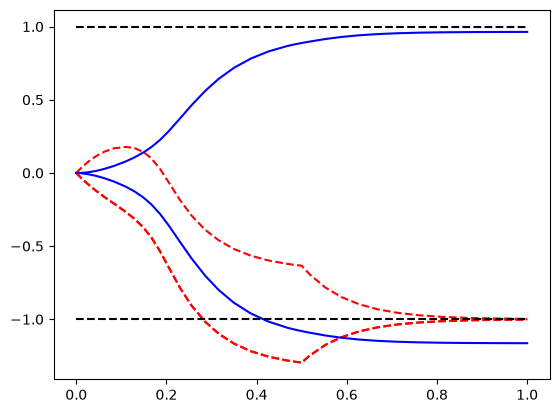

In [37]:
plt.plot(output.t,output.y[0:nFeatures].T,'r--')
plt.plot(output.t,output.y[nFeatures:].T/nFeatures,'b-')
plt.plot(tlimits,[1,1],'k--')
plt.plot(tlimits,[-1,-1],'k--')

(39, 3)


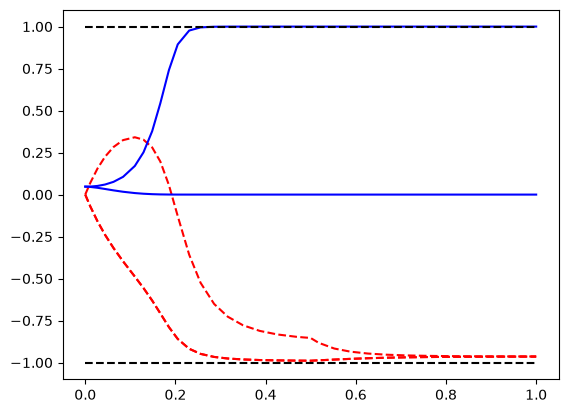

In [38]:
#Transform that into activations rather than internal states
yFeatures = output.y[0:nFeatures].T
for i in range(np.shape(yFeatures)[0]):
    yFeatures[i,:] = f_feature(yFeatures[i,:])
yMemories = output.y[nFeatures:].T
for i in range(np.shape(yMemories)[0]):
    yMemories[i,:] = f_memory(yMemories[i,:])
print(np.shape(yFeatures))
plt.plot(output.t,yFeatures,'r--')
plt.plot(output.t,yMemories,'b-')
plt.plot(tlimits,[1,1],'k--')
plt.plot(tlimits,[-1,-1],'k--')